## **EDA**
- Data Transformation
- Feature Engineering
- Exploration Insights
- Feature Selection
- Data Preprocessing in insurance industry

In [1]:
import pandas as pd

In [2]:
data = pd.read_csv(r"C:\Users\LENOVO\Downloads\insurance.csv")
data.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [3]:
data.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [4]:
# There is no NAN values 
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB


## **Why Data Transformation Is Required**
### **What is Data Transformation**
It is the process of converting raw data into a more suitable format or scale to improve performance and accuaracy in analysis.


Text(10000, 200, 'Right skewed Data')

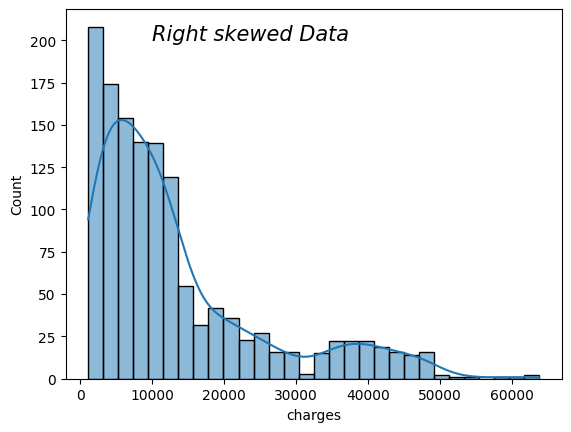

In [20]:
import numpy as np
import seaborn as sns 
import matplotlib.pyplot as plt
sns.histplot(data['charges'],kde=True) # Before Imputation
plt.text(10000,200,"Right skewed Data",fontsize = 15,style = 'italic')

In [21]:
# Box_Cox on positive BMI
from scipy.stats import boxcox
data['bmi_boxcox'],_= boxcox(data['bmi']+1)

<Axes: xlabel='log_charges', ylabel='Count'>

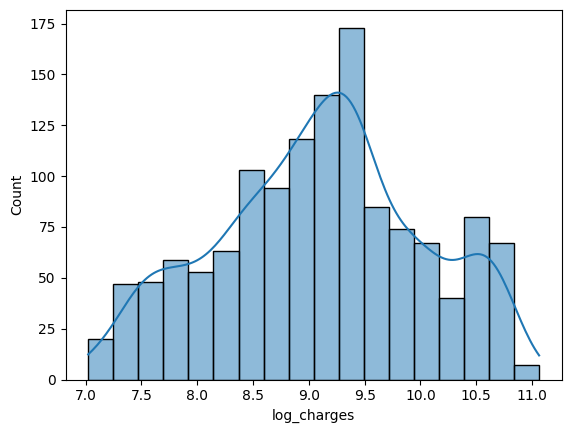

In [22]:
data['log_charges'] = np.log1p(data['charges'])
sns.histplot(data['log_charges'],kde=True) # After imputation

In [23]:
data.shape

(1338, 9)

In [24]:
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,7.912470,8.260455


In [ ]:
#Inferance: The transformed distribution is more symmetric, which is better for regression and visualization.
##IN statistics whenever histogram is dhowing data distribution in form of  bell shape curve,
### it is normal distribution, otherwise skewed distribution

## **Feature Engineering**

Create meaningful features

features: columns

## **Common Types of Feature Engineering**
1. Feature Creation: Creating new features from existing data.
2. Feature Transformation: Changing feature values to a better form.
3. Feature Encoding: Changing data into numeric form

In [25]:
# Before appplying feature engineering
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137
4,32,male,28.880,0,no,northwest,3866.85520,7.912470,8.260455


In [ ]:
# Creating category as per bmi and age

In [26]:
data['bmi_cat'] = pd.cut(data['bmi'],bins=[0,18.5,25,30,100],labels=['under','normal','over','obese'])

In [27]:
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges,bmi_cat
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236,over
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882,obese
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763,obese
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137,normal
4,32,male,28.880,0,no,northwest,3866.85520,7.912470,8.260455,over


In [29]:
data['age_group'] = pd.cut(data['age'],bins=[17,30,45,60,100],labels=['young','adult','mature','senior'])

In [31]:
data.head(4)

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges,bmi_cat,age_group
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236,over,young
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882,obese,young
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763,obese,young
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137,normal,adult


In [32]:
data['age_smoker'] = data['age']* (data['smoker']=="yes")

In [34]:
# After Feature Engineering
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges,bmi_cat,age_group,age_smoker
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236,over,young,19
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882,obese,young,0
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763,obese,young,0
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137,normal,adult,0
4,32,male,28.880,0,no,northwest,3866.85520,7.912470,8.260455,over,adult,0


## **Data Distribution Analysis**
Transform distributions help us better understand data patterns reduce skewness.

Boxplots are idel for comparing how different groups affect a contineous variable

<Axes: xlabel='log_charges', ylabel='Count'>

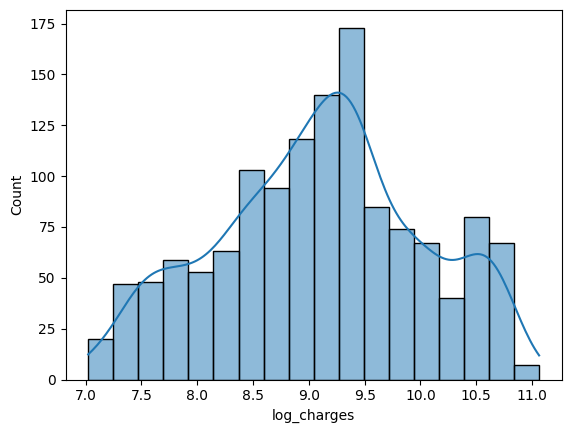

In [36]:
# Distribution plots
sns.histplot(data['log_charges'],kde=True)

<Axes: xlabel='bmi_boxcox', ylabel='Count'>

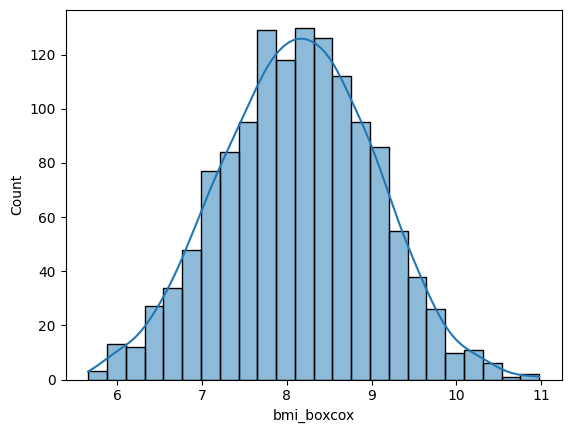

In [37]:
sns.histplot(data['bmi_boxcox'],kde=True)

## **Inferance**
This plot shows the distribution of expenses after applying a log transformation

Originally, the data was right-skewed,meaning most people had low expenses but a few had very high ones.

Log transformation makes the distribution more normal and symmetric-ideal for many statistical and machine learning models.

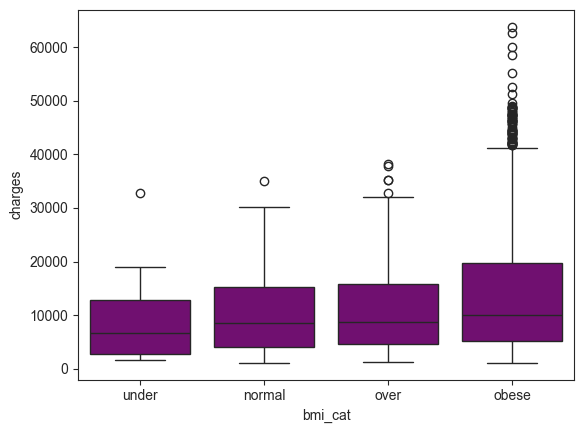

In [ ]:
# Boxplot for categorical distributions
sns.boxplot(x='bmi_cat',y='charges',data=data,color='purple')

In [ ]:
# Inferance :
## this boxplot compares insurance expenses across BMI categories.
# We can see the "obese" category have many outliers the average and variation in expenses tend to increase
## This implies that higher BMI is associated with higher medical costs.

<Axes: xlabel='smoker', ylabel='charges'>

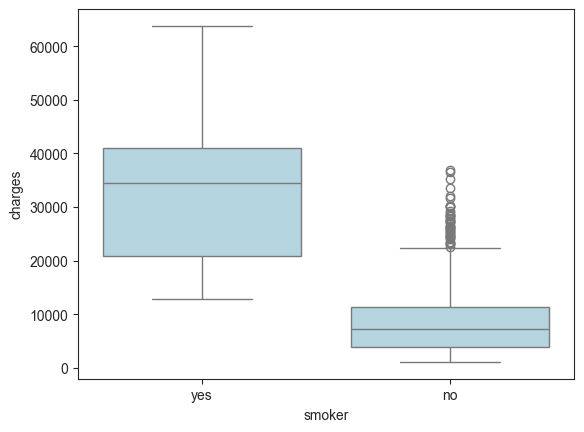

In [51]:
sns.boxplot(x='smoker',y='charges',data=data,color='lightblue')

In [52]:
## Inferance:
## it is clear that smoker have higher expenses than non-smokers.
## Not only the median higher but the spreadis also higher -indicating that smoking is amajor cost driver in medical insurance.
### This kind of visualization is critical for risk segmentation in the insurance industry.

In [53]:
data.head()

,age,sex,bmi,children,smoker,region,charges,bmi_boxcox,log_charges,bmi_cat,age_group,age_smoker
0,19,female,27.900,0,yes,southwest,16884.92400,7.763291,9.734236,over,young,19
1,18,male,33.770,1,no,southeast,1725.55230,8.618976,7.453882,obese,young,0
2,28,male,33.000,3,no,southeast,4449.46200,8.511576,8.400763,obese,young,0
3,33,male,22.705,0,no,northwest,21984.47061,6.920914,9.998137,normal,adult,0
4,32,male,28.880,0,no,northwest,3866.85520,7.912470,8.260455,over,adult,0


<Axes: >

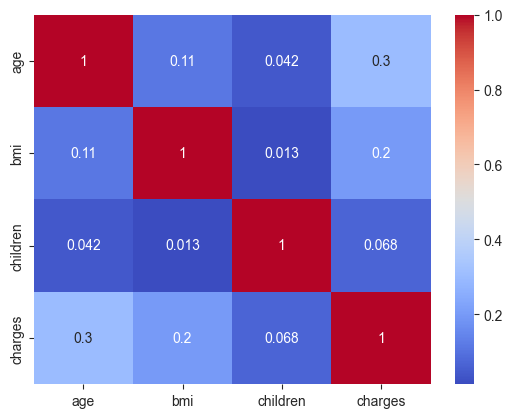

In [54]:
num_cols= ['age','bmi','children','charges']
corr=data[num_cols].corr()
sns.heatmap(corr,annot=True,cmap='coolwarm')

## **Check unique values for categorical fields:**

In [56]:
for col in ['sex','smoker','region','bmi_cat','age_group']:
    print(col,data[col].value_counts())
    print()

sex sex
male      676
female    662
Name: count, dtype: int64

smoker smoker
no     1064
yes     274
Name: count, dtype: int64

region region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

bmi_cat bmi_cat
obese     705
over      386
normal    226
under      21
Name: count, dtype: int64

age_group age_group
young     444
mature    409
adult     394
senior     91
Name: count, dtype: int64



## **Target Variable Distribution**

<Axes: xlabel='charges', ylabel='Count'>

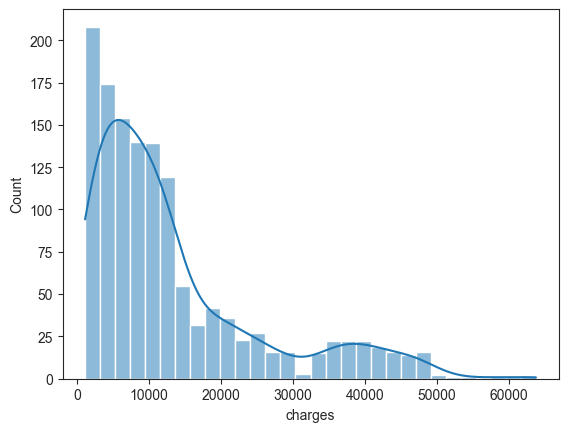

In [57]:
sns.histplot(data['charges'],kde=True)

<Axes: xlabel='log_charges', ylabel='Count'>

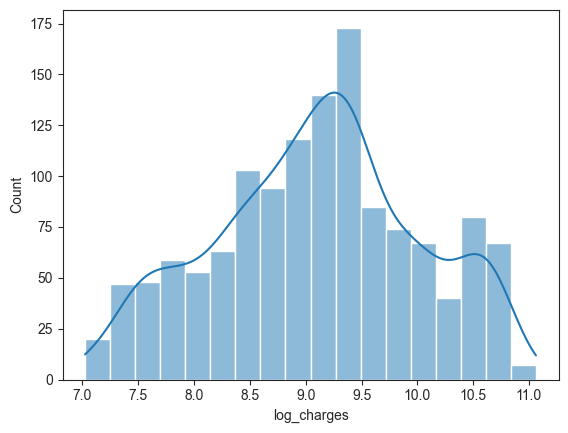

In [58]:
sns.histplot(data['log_charges'],kde=True)